# Unsupervised Learning: K-Means Clustering

**DCS 404 · Data Science and Machine Learning**

---

Every model this course has built so far learned from an answer key. Linear regression had `sales`, logistic
regression had `admit`, decision trees had `Outcome` — some column $y$ the model was trained to predict, and
some notion of "correct" it was graded against. Today that answer key disappears. We're handed a table of
features and nothing else, and the question changes from *what's the right label?* to *does this data have
any structure at all — and if so, what does it look like?*

That's **unsupervised learning**, and **clustering** is its most common form: grouping observations so that
similar ones end up together and dissimilar ones end up apart, with no labels to check our work against. This
module covers **K-Means**, by far the most widely used clustering algorithm — simple enough to implement from
scratch in a dozen lines, and the right first stop before the more exotic clustering methods (hierarchical,
density-based) that build on the same core idea.

## How to work through this

Run every code cell in order (`Shift + Enter`); later sections reuse the synthetic dataset built in Setup.
This module leans on ideas from earlier in the course — Euclidean distance from the K-Nearest Neighbors
module, feature standardisation from Gradient Descent, the train-many-models-and-compare-a-score pattern from
Evaluation Metrics — without re-deriving any of them.

One scope note: clustering is a big field, and this module deliberately covers **one algorithm well** rather
than many algorithms shallowly. K-Means variants (K-Medoids, K-Modes, Mini-Batch K-Means) and entirely
different clustering families (hierarchical, density-based) are real and useful, but they're future
material — Section 7 points to exactly where they'd fit in.

## Learning objectives

After completing this module you will be able to:

- Explain what makes clustering *unsupervised*, and contrast it with the classification/regression problems
  from earlier modules.
- State the K-Means objective function (inertia / sum of squared distances to centroid) and explain why it's
  optimized by **coordinate descent** rather than gradient descent.
- Implement K-Means from scratch — assign, update, repeat — and verify it against scikit-learn.
- Explain why centroid initialization matters, and how **K-Means++** fixes the worst failures of random
  initialization.
- Choose the number of clusters $K$ using the **elbow method** and the **silhouette score**.
- Apply K-Means to a real dataset and interpret the resulting clusters.
- Describe K-Means' key assumption (roughly spherical, similarly-sized clusters) and recognise when it fails.

## Setup

Run this once. Libraries, the usual plotting style, and one synthetic dataset — four well-separated blobs —
reused for most of this module.

300 points, 2 features, generated from 4 true clusters


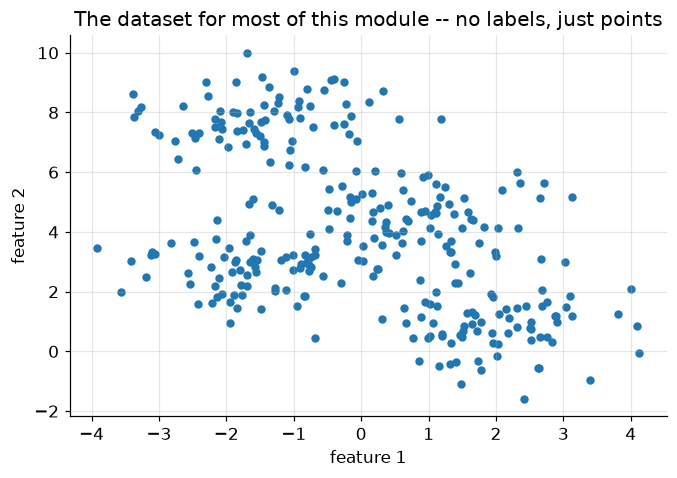

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})
sns.set_palette("deep")
RANDOM_STATE = 0

# Four well-separated blobs -- small and synthetic on purpose, so every plot stays readable
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.9, random_state=RANDOM_STATE)
print(f"{X.shape[0]} points, {X.shape[1]} features, generated from {len(set(y_true))} true clusters")

plt.scatter(X[:, 0], X[:, 1], s=20, color="tab:blue")
plt.title("The dataset for most of this module -- no labels, just points")
plt.xlabel("feature 1"); plt.ylabel("feature 2")
plt.show()

---
## 1. From "which label?" to "what groups?"

Imagine visiting a zoo for the first time with no idea what any of the animals are called. You'd still
notice that some animals live in water, some fly, some live underground — and without ever being told a
single species name, you could sort the animals into sensible groups just from what you observe.

<div align="center">
<img src="resources/images/cluster_animal_grouping_analogy.png" height="320">

*Figure 1 — Grouping by observed similarity, with no labels at all.*
</div>

That's **clustering**: partitioning observations into groups so that points in the same group are similar
and points in different groups are dissimilar — using only the features, never a label. It's the most common
form of **unsupervised learning**, the branch of machine learning that finds structure in unlabeled data
rather than predicting a known target.

Clustering looks superficially like classification — both end with "this point belongs to group $k$" — but
the two solve different problems. Classification learns a boundary from examples that already carry the
correct answer; clustering has no correct answer to learn from, only the geometry of the points themselves.
That absence of ground truth will matter again in Section 5: without labels, "how good is this clustering?"
becomes its own, genuinely harder question.

Clustering algorithms come in several families, each built around a different notion of "similar":
**partition-based** (today's topic — divide the data into $K$ groups, each represented by a centroid),
**hierarchical** (build a tree of nested clusters, cut it wherever makes sense), and **density-based** (a
cluster is any densely-packed region, however oddly shaped, separated from others by sparse space). This
module focuses entirely on the first family — specifically **K-Means** — because it's the algorithm nearly
every other clustering method is explained in contrast to.

---
## 2. The K-Means algorithm

K-Means represents each of $K$ clusters by a single point — its **centroid** — and assigns every observation
to whichever centroid is closest. Formally, given data points $\mathbf x_1, \dots, \mathbf x_N$, K-Means finds
cluster assignments $\boldsymbol c$ and centroids $\boldsymbol \mu_1, \dots, \boldsymbol \mu_K$ that minimise

$$\mathcal J = \sum_{k=1}^{K} \sum_{i:\, c_i = k} \left\| \mathbf x_i - \boldsymbol \mu_k \right\|_2^2$$

— the total squared distance from every point to its own cluster's centroid. This quantity has a few
names worth recognising in the wild: **inertia**, **within-cluster sum of squares (WCSS)**, or just the
K-Means objective. Small $\mathcal J$ means every point sits close to its centroid — tight, compact clusters.

Two unknowns sit inside $\mathcal J$ at once — the assignments $\boldsymbol c$ *and* the centroids
$\boldsymbol \mu$ — and they depend on each other, which rules out plain gradient descent (there's no single
gradient to follow when the thing you're optimizing over includes a discrete assignment). The fix is
**coordinate descent**: fix one set of unknowns, optimize the other exactly, then swap. K-Means alternates two
steps, each of which has a simple, exact solution:

1. **Assign** — with centroids fixed, send each point to its nearest centroid:
   $$c_i \leftarrow \underset{k}{\arg\min} \left\| \mathbf x_i - \boldsymbol \mu_k \right\|_2^2$$
2. **Update** — with assignments fixed, recompute each centroid as the mean of the points now assigned to it:
   $$\boldsymbol \mu_k \leftarrow \frac{1}{|\{i : c_i = k\}|} \sum_{i:\, c_i = k} \mathbf x_i$$

Repeat until nothing changes. Each step can only decrease $\mathcal J$ (Step 1 by construction sends every
point to its *closest* centroid; Step 2 by construction sets each centroid to the mean that *minimises*
squared distance to its own cluster) — so $\mathcal J$ falls monotonically and the algorithm is guaranteed to
converge, in finite steps, to *some* stable assignment. Not necessarily the best one, though — $\mathcal J$
is non-convex, so different starting points can converge to different (and sometimes much worse) stable
points. Section 4 shows exactly how much that can matter.

---
## 3. K-Means from scratch

Assign, update, repeat — that's genuinely the whole algorithm. Let's write it directly from Section 2's two
steps and check it against scikit-learn's implementation on the same data.

In [2]:
def kmeans(X, k, n_iter=100, seed=RANDOM_STATE):
    '''Lloyd's algorithm: assign points to the nearest centroid, recompute centroids, repeat.'''
    rng = np.random.default_rng(seed)
    centroids = X[rng.choice(len(X), size=k, replace=False)]   # Forgy init: k real data points

    for _ in range(n_iter):
        # Assign step: distance from every point to every centroid, then the closest one
        distances = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
        labels = distances.argmin(axis=1)

        # Update step: each centroid becomes the mean of the points now assigned to it
        new_centroids = np.array([X[labels == j].mean(axis=0) for j in range(k)])

        if np.allclose(new_centroids, centroids):   # nothing moved -- converged
            break
        centroids = new_centroids

    inertia = sum(np.sum((X[labels == j] - centroids[j]) ** 2) for j in range(k))
    return centroids, labels, inertia

centroids, labels, inertia = kmeans(X, k=4)
print(f"from-scratch inertia: {inertia:.2f}")

sk_model = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10).fit(X)
print(f"scikit-learn inertia: {sk_model.inertia_:.2f}")

from-scratch inertia: 454.38
scikit-learn inertia: 454.38


The two numbers match to several decimal places — our dozen-line implementation is doing exactly what
scikit-learn's `KMeans` does internally (which is itself called **Lloyd's algorithm**, after the 1957/1982
paper that first described it). Let's look at what it actually found.

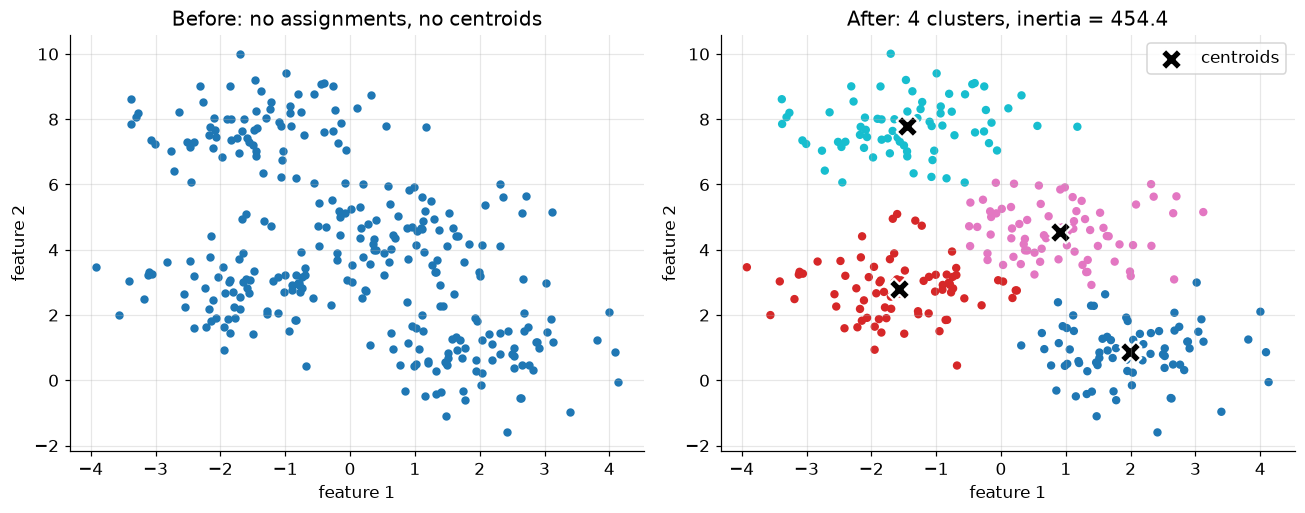

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

axes[0].scatter(X[:, 0], X[:, 1], s=20, color="tab:blue")
axes[0].set_title("Before: no assignments, no centroids")

axes[1].scatter(X[:, 0], X[:, 1], c=labels, cmap="tab10", s=20)
axes[1].scatter(centroids[:, 0], centroids[:, 1], marker="X", s=200,
                c="black", edgecolor="white", linewidth=1.5, label="centroids")
axes[1].set_title(f"After: {4} clusters, inertia = {inertia:.1f}")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
plt.tight_layout()
plt.show()

Four tight, well-separated groups, each with a centroid sitting at its visual centre — exactly what we'd
sketch by eye on this data. That's a fair test, though: these blobs were generated to be easy. Section 6
brings in a real dataset where the "right" grouping isn't obvious just from looking.

---
## 4. Why initialization matters: K-Means++

`kmeans` above starts from $K$ randomly chosen data points (**Forgy initialization**) and never looks back.
Section 2 already flagged the risk: coordinate descent only guarantees *a* stable point, not *the best* one.
Let's force a bad draw and watch what happens.

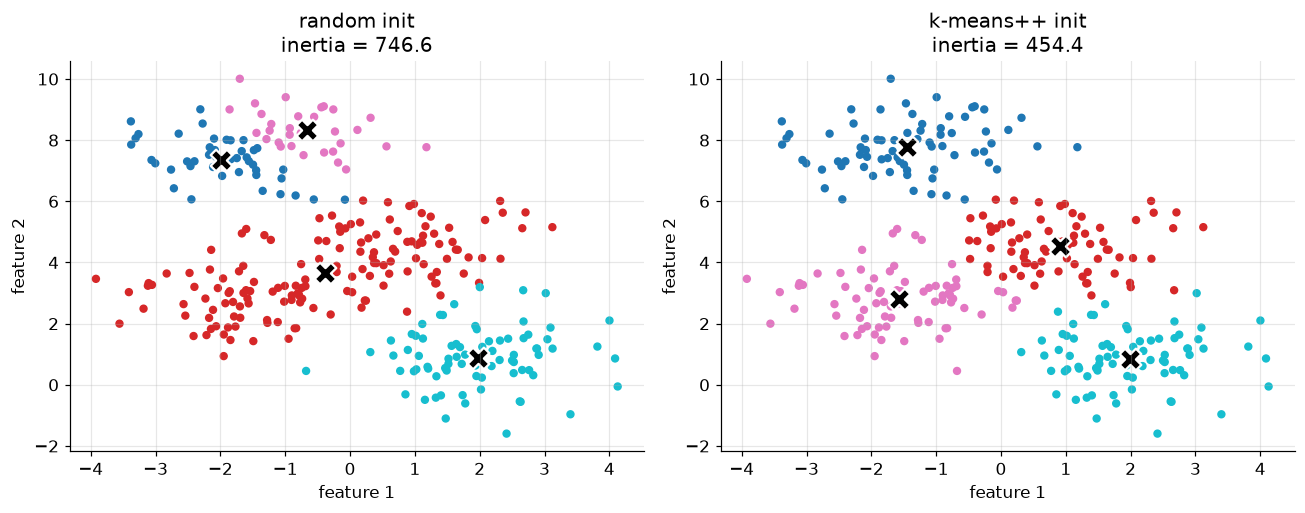

random init inertia:    746.6
k-means++ init inertia: 454.4


In [4]:
random_init = KMeans(n_clusters=4, init="random", n_init=1, random_state=5).fit(X)
smart_init = KMeans(n_clusters=4, init="k-means++", n_init=1, random_state=5).fit(X)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, model, name in zip(axes, [random_init, smart_init], ["random init", "k-means++ init"]):
    ax.scatter(X[:, 0], X[:, 1], c=model.labels_, cmap="tab10", s=20)
    ax.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
               marker="X", s=200, c="black", edgecolor="white", linewidth=1.5)
    ax.set_title(f"{name}\ninertia = {model.inertia_:.1f}")
    ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
axes[0].set_ylabel("feature 2")
plt.tight_layout()
plt.show()

print(f"random init inertia:    {random_init.inertia_:.1f}")
print(f"k-means++ init inertia: {smart_init.inertia_:.1f}")

Same data, same $K$, same number of iterations to converge — a single unlucky starting draw left two
centroids fighting over one cluster while a different cluster got none of its own, and coordinate descent
dutifully converged to that arrangement anyway, because nothing *local* told it to do otherwise.

**K-Means++** fixes this by making initialization itself a little smarter, without touching the assign/update
loop at all:

1. Pick the first centroid uniformly at random from the data.
2. For every other point, compute its squared distance to the *nearest centroid chosen so far*.
3. Pick the next centroid randomly, but weighted so that far-away points are more likely to be chosen.
4. Repeat 2-3 until $K$ centroids are chosen.

The effect is centroids that start out spread across the data rather than clumped together by chance — points
far from every existing centroid are exactly the points most likely to belong to a cluster that has no
centroid yet. It's still random (so still not a global-optimum guarantee), but the failure mode above becomes
far less likely. It's also scikit-learn's **default**: plain `KMeans(n_clusters=k)` already uses
`init="k-means++"` unless told otherwise, and in practice is run several times from different seeds anyway
(`n_init`, default 10 in recent scikit-learn), keeping whichever run reaches the lowest inertia. From here on,
every `KMeans` call in this module leaves both settings at their defaults.

---
## 5. Choosing $K$: the elbow method and the silhouette score

Every example so far quietly assumed $K=4$ — because we generated the data and already knew the answer. Real
data never comes with a "true number of clusters" label attached, and that absence of ground truth is the
central difficulty Section 1 warned about: K-Means will happily produce *some* clustering for any $K$ you
hand it, correct or not.

One number that will **not** help: inertia alone. It decreases every single time $K$ grows — push $K$ all
the way to $N$ (one cluster per point) and inertia hits exactly zero, which is obviously not a useful
clustering. What inertia's *shape* can tell us is when adding another cluster stops buying much:

<div align="center">
<img src="resources/images/cluster_workflow_pipeline.png" width="640">

*Figure 2 — The clustering workflow: Sections 2-4 built the "Clustering Algorithm" box, this section is
"Cluster Validation," and Section 6 is "Result Interpretation."*
</div>

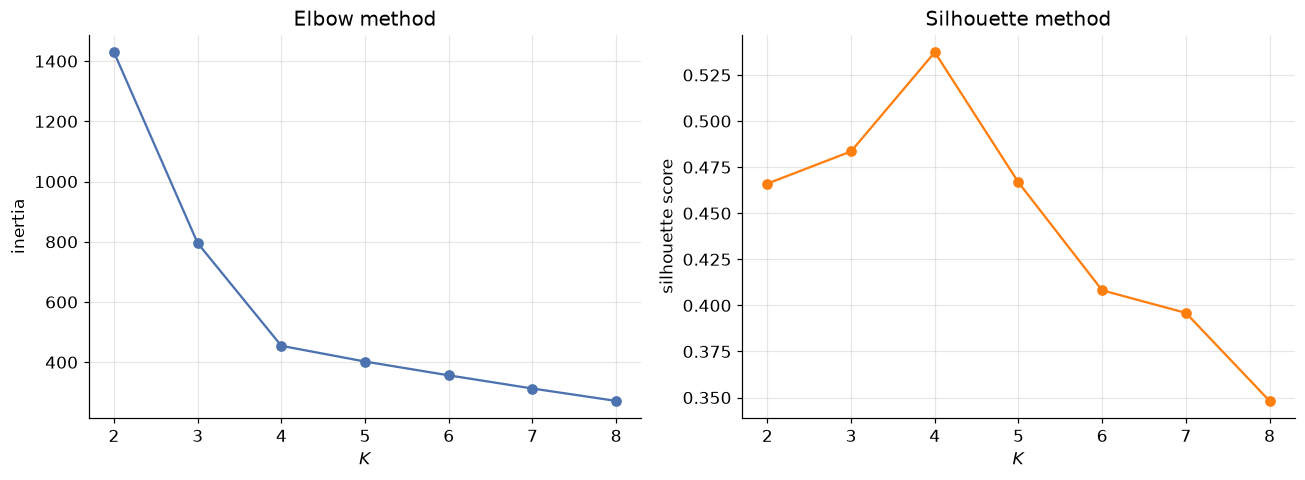

silhouette score peaks at K = 4


In [5]:
Ks = range(2, 9)
inertias = []
silhouettes = []

for k in Ks:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X, model.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(Ks, inertias, marker="o")
axes[0].set_xlabel("$K$"); axes[0].set_ylabel("inertia")
axes[0].set_title("Elbow method")

axes[1].plot(Ks, silhouettes, marker="o", color="tab:orange")
axes[1].set_xlabel("$K$"); axes[1].set_ylabel("silhouette score")
axes[1].set_title("Silhouette method")

plt.tight_layout()
plt.show()

best_k = Ks[int(np.argmax(silhouettes))]
print(f"silhouette score peaks at K = {best_k}")

The **elbow method** looks for the point where the inertia curve stops falling steeply and starts to flatten
— the "elbow" — reasoning that clusters beyond that point are splitting real structure into pieces rather
than capturing anything new. It's a judgment call read off a picture, which is exactly its weakness: not
every dataset produces an obvious elbow.

The **silhouette score** is a real number, not a picture, and it doesn't need inertia's "always decreasing"
caveat. For a single point $\mathbf x_i$, define $a(\mathbf x_i)$ as its mean distance to every other point in
its *own* cluster (small = tightly packed), and $b(\mathbf x_i)$ as its mean distance to the points of the
*nearest other* cluster (large = well separated from its neighbours). The silhouette coefficient is

$$s(\mathbf x_i) = \frac{b(\mathbf x_i) - a(\mathbf x_i)}{\max\left(a(\mathbf x_i), b(\mathbf x_i)\right)}$$

which lives in $[-1, 1]$: close to $1$ means a point sits comfortably inside its own tight cluster, far from
any other; close to $0$ means it's sitting right on a boundary; negative means it's arguably in the *wrong*
cluster. `silhouette_score` averages $s(\mathbf x_i)$ over every point, giving one number per value of $K$ —
and here it peaks exactly at the true $K=4$, agreeing with both the elbow and the ground truth we generated
the data with.

---
## 6. Real data: clustering diabetes patients

The **Pima Indians Diabetes dataset** returns from the Classification module — 768 patients, each with
physiological measurements and a `diabetes / no diabetes` label. Last time, that label was the target a
classifier learned to predict. This time we throw it away entirely and ask a different question: **ignoring
the outcome, does K-Means find any natural grouping in the measurements themselves?**

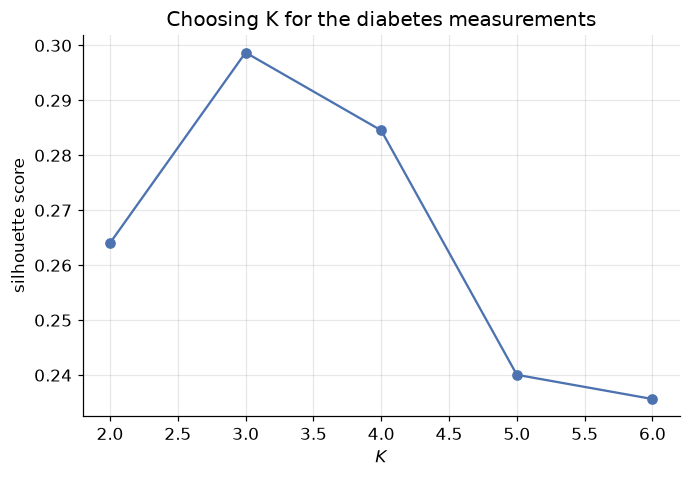

{2: 0.264, 3: 0.299, 4: 0.285, 5: 0.24, 6: 0.236}


In [6]:
def load_csv(name, **kwargs):
    for candidate in [Path(f"data/{name}"), Path(f"notebooks/data/{name}")]:
        if candidate.exists():
            return pd.read_csv(candidate, **kwargs)
    raise FileNotFoundError(f"Could not find {name}")

diabetes = load_csv("diabetes.csv")
features = ["Glucose", "BMI", "Age", "BloodPressure"]
X_diab = diabetes[features].values

# Standardise -- Glucose (0-199) and Age (21-81) live on very different scales,
# and K-Means' Euclidean distance treats every feature's units as equally important
X_diab_scaled = StandardScaler().fit_transform(X_diab)

diab_Ks = range(2, 7)
diab_silhouettes = [
    silhouette_score(X_diab_scaled, KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_diab_scaled).labels_)
    for k in diab_Ks
]
plt.plot(diab_Ks, diab_silhouettes, marker="o")
plt.xlabel("$K$"); plt.ylabel("silhouette score")
plt.title("Choosing K for the diabetes measurements")
plt.show()

print({k: round(s, 3) for k, s in zip(diab_Ks, diab_silhouettes)})

Real data rarely hands you as clean an answer as the synthetic blobs did. The silhouette score edges slightly
higher at $K=3$ than $K=2$, but the two are close, and $K=2$ produces a split simple enough to actually
interpret — a good reminder that the highest score on a chart is a *suggestion*, not a verdict; domain
judgment about what's useful still gets a vote. Let's fit $K=2$ and see what it found.

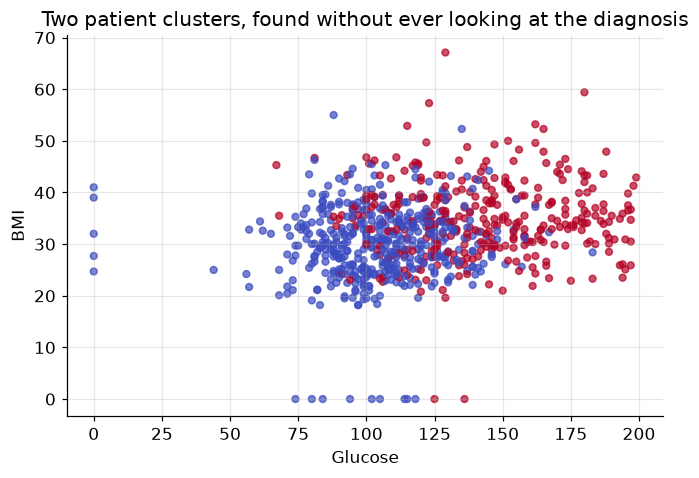

,Glucose,BMI,Age,BloodPressure
cluster,,,,
0,104.4,29.8,27.0,61.8
1,142.9,34.9,41.6,78.8


In [7]:
kmeans_diab = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10).fit(X_diab_scaled)
diabetes["cluster"] = kmeans_diab.labels_

plt.scatter(diabetes["Glucose"], diabetes["BMI"], c=diabetes["cluster"], cmap="coolwarm", s=20, alpha=0.7)
plt.xlabel("Glucose"); plt.ylabel("BMI")
plt.title("Two patient clusters, found without ever looking at the diagnosis")
plt.show()

diabetes.groupby("cluster")[features].mean().round(1)

One cluster runs consistently higher on every one of these four measurements than the other — K-Means found
a real physiological split using nothing but distances in feature space. Now, and only now, let's check it
against the diagnosis we deliberately withheld:

In [8]:
crosstab = pd.crosstab(diabetes["cluster"], diabetes["Outcome"])
crosstab.columns = ["no diabetes", "diabetes"]
crosstab.index = [f"cluster {i}" for i in crosstab.index]
print(crosstab)

diabetes_rate = diabetes.groupby("cluster")["Outcome"].mean()
for cluster_id, rate in diabetes_rate.items():
    print(f"cluster {cluster_id}: {rate:.1%} of patients have diabetes")

           no diabetes  diabetes
cluster 0          356        83
cluster 1          144       185
cluster 0: 18.9% of patients have diabetes
cluster 1: 56.2% of patients have diabetes


The cluster with the *higher* Glucose/BMI/Age/BloodPressure profile also has the far higher diabetes rate —
unsupervised structure, discovered with zero access to the label, lines up with a diagnosis that carries real
clinical meaning. That's not a coincidence and it's not magic: diabetes risk genuinely correlates with these
measurements, so a grouping built purely from their geometry was always likely to shadow it. This is exactly
how clustering earns its keep in practice — as an exploratory tool that surfaces structure worth
investigating further, not as a replacement for the labelled classifier from the Classification module.

---
## 7. Where K-Means struggles

K-Means' assign step always draws a straight-line (Euclidean) boundary between neighbouring centroids, which
bakes in an assumption worth stating plainly: it works best when clusters are **roughly round and similar in
size**. Real structure that violates that assumption breaks it, visibly.

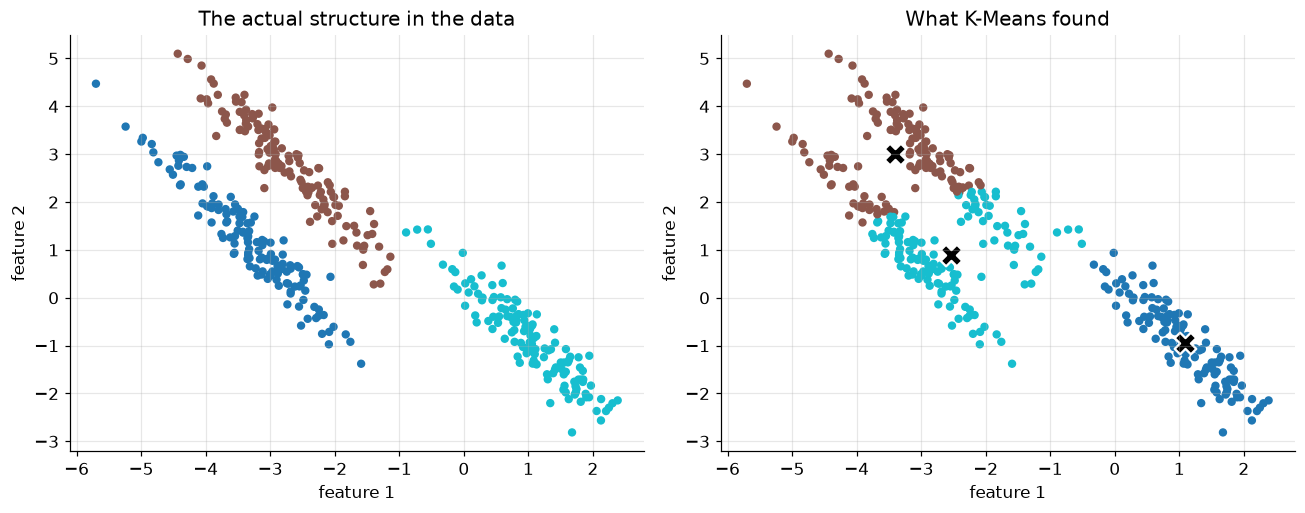

In [9]:
X_round, y_round = make_blobs(n_samples=400, centers=3, random_state=170)
stretch = [[0.6, -0.6], [-0.4, 0.8]]     # a linear transform that stretches the blobs diagonally
X_stretched = X_round @ stretch

kmeans_stretched = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10).fit(X_stretched)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].scatter(X_stretched[:, 0], X_stretched[:, 1], c=y_round, cmap="tab10", s=20)
axes[0].set_title("The actual structure in the data")

axes[1].scatter(X_stretched[:, 0], X_stretched[:, 1], c=kmeans_stretched.labels_, cmap="tab10", s=20)
axes[1].scatter(kmeans_stretched.cluster_centers_[:, 0], kmeans_stretched.cluster_centers_[:, 1],
                marker="X", s=200, c="black", edgecolor="white", linewidth=1.5)
axes[1].set_title("What K-Means found")

for ax in axes:
    ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
plt.tight_layout()
plt.show()

The left panel is the true structure — three elongated, diagonal clusters. The right panel is K-Means'
answer with the correct $K=3$: it slices straight through clusters that are genuinely stretched, because a
centroid-and-Euclidean-distance model can only ever draw round-ish decision regions, no matter how well $K$
is chosen or how carefully centroids are initialised. This isn't a bug to patch with a better seed — it's the
algorithm's central assumption showing its limit.

A few other situations worth knowing about, without needing to solve them today:

- **Outliers** distort centroids badly, since a centroid is a *mean*, and means are notoriously sensitive to
  extreme values (the same reason the Regression module cared about outliers). K-Medoids — using an actual
  data point, the *medoid*, as each cluster's representative instead of a computed mean — is the standard fix.
- **Unscaled features** silently let whichever feature has the largest numeric range dominate every distance
  calculation. Section 6 standardised the diabetes features for exactly this reason — the same lesson the
  Gradient Descent module taught about optimization applies just as directly to distance-based clustering.
- **Non-round clusters**, as just demonstrated, are where **density-based** methods (DBSCAN and relatives)
  take over — they define a cluster as a dense region of any shape, with no centroid and no assumption of
  roundness at all. **Hierarchical clustering** sidesteps choosing $K$ upfront entirely, building a full tree
  of nested clusters and letting you pick the cut afterward. Both are natural next modules once K-Means feels
  comfortable.

---
## 8. Your turn

Add cells below each exercise. Exercises 2 and 4 are the ones that consolidate the big ideas.

**Exercise 1 — Verify the update step by hand.**
Take the `centroids` and `labels` from Section 3's `kmeans(X, k=4)` run. For cluster `0`, manually compute
`X[labels == 0].mean(axis=0)` and confirm it matches `centroids[0]`. Explain in one sentence why this must
always be true the moment the loop has converged.

**Exercise 2 — How much does a bad seed cost, on average?**
Section 4 showed one dramatic random-init failure at `random_state=5`. Loop `random_state` from 0 to 29 with
`init="random", n_init=1`, record each run's inertia, and compare the distribution against the same sweep with
`init="k-means++"`. What fraction of random-init runs land more than 20% above the best k-means++ run?

**Exercise 3 — Silhouette by hand for one point.**
Pick any single point from the Section 5 blobs at $K=4$. Manually compute $a(\mathbf x_i)$ (mean distance to
its own cluster) and $b(\mathbf x_i)$ (mean distance to the nearest other cluster) using NumPy, then compute
$s(\mathbf x_i)$ and check it against `sklearn.metrics.silhouette_samples(X, labels)[i]`.

**Exercise 4 — Cluster the full diabetes feature set.**
Section 6 used only four of the eight diabetes features. Refit K-Means (with standardisation) on all eight,
re-run the silhouette sweep, and compare the chosen $K$ and the resulting cluster-vs-Outcome crosstab against
Section 6's result. Did more features sharpen the split or blur it?

**Exercise 5 — Watch K-Means fail on circles.**
Generate two concentric circles with `sklearn.datasets.make_circles(n_samples=300, noise=0.05, factor=0.5)`
and fit K-Means with `K=2`. Plot the result. Explain, using Section 7's "roughly round, similarly sized"
assumption, exactly why K-Means cannot succeed here no matter how it's initialised — and what a density-based
method would need to look at instead of centroids to get it right.

---
## 9. If you remember nothing else

1. **Clustering is unsupervised** — grouping data by similarity alone, with no label to train against or
   check against. That absence of ground truth is what makes "is this a good clustering?" a genuinely
   harder question than any supervised metric from the Evaluation Metrics module.

2. **K-Means minimises inertia** — total squared distance from every point to its cluster's centroid — by
   **coordinate descent**: repeatedly assign points to their nearest centroid, then move each centroid to the
   mean of its assigned points, until nothing changes.

3. K-Means is **guaranteed to converge**, monotonically decreasing its objective every step, but **not
   guaranteed to reach the best solution** — the objective is non-convex, so a poor starting point can trap
   it in a visibly worse stable arrangement.

4. **K-Means++** initialises centroids by preferring points far from ones already chosen, sharply reducing
   (though not eliminating) the chance of a bad local optimum. It's scikit-learn's default, alongside running
   several random restarts (`n_init`) and keeping the best.

5. Choosing $K$: **inertia always decreases** as $K$ grows, so it's read as a *shape* (the elbow method,
   inexact) rather than a single number. The **silhouette score** — how much closer a point is to its own
   cluster than to its nearest neighbour cluster — gives one comparable number per $K$ and doesn't share that
   always-decreasing flaw.

6. **Standardise features before clustering** — Euclidean distance treats every feature's raw numeric scale
   as equally important, exactly the lesson the Gradient Descent module taught about optimization.

7. K-Means assumes clusters are **roughly round and similarly sized**; elongated, unevenly-sized, or
   non-convex structure breaks it visibly, no matter how carefully $K$ or the initialisation is chosen. That's
   what hierarchical and density-based clustering exist to handle instead.

8. On real data (Pima diabetes measurements), K-Means found a two-group split, built with zero access to the
   diagnosis label, that lined up with a meaningfully different diabetes rate between groups — clustering's
   actual job: surfacing structure worth investigating, not replacing a trained classifier.

---
## 10. Further reading and glossary

### Further reading

- Stuart Lloyd (1982), [*Least Squares Quantization in PCM*](
  https://doi.org/10.1109/TIT.1982.1056489) — the paper behind "Lloyd's algorithm," the assign/update loop
  this module implemented from scratch.
- David Arthur & Sergei Vassilvitskii (2007), [*k-means++: The Advantages of Careful Seeding*](
  http://ilpubs.stanford.edu:8090/778/1/2006-13.pdf) — the original K-Means++ paper.
- scikit-learn's guide to [clustering](https://scikit-learn.org/stable/modules/clustering.html) — every
  algorithm mentioned in Section 7 (and many more), with the assumptions and trade-offs of each.
- scikit-learn's [K-Means assumptions example](
  https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_assumptions.html) — the anisotropic-blob
  demonstration Section 7 adapted, alongside a few other failure modes worth seeing.
- Peter J. Rousseeuw (1987), [*Silhouettes: A Graphical Aid to the Interpretation and Validation of Cluster
  Analysis*](https://doi.org/10.1016/0377-0427(87)90125-7) — the original silhouette-score paper.

### Glossary

| Term | Meaning |
|---|---|
| Unsupervised learning | Learning structure from data with no target label to train or validate against. |
| Clustering | Partitioning observations into groups of similar points, with no ground-truth grouping given. |
| Centroid | The point (typically the mean) representing a cluster in partition-based clustering. |
| Inertia / WCSS | K-Means' objective: total squared distance from every point to its cluster's centroid. |
| Coordinate descent | Optimizing by alternately fixing one set of parameters and solving exactly for the other. |
| Lloyd's algorithm | The classic assign-then-update loop that implements K-Means. |
| Forgy initialization | Initializing centroids as $K$ randomly chosen data points. |
| K-Means++ | An initialization scheme that prefers centroids far from ones already chosen. |
| `n_init` | The number of random restarts scikit-learn's `KMeans` runs, keeping the lowest-inertia result. |
| Elbow method | Choosing $K$ by eye, from where the inertia-vs-$K$ curve stops falling steeply. |
| Silhouette score | A $[-1,1]$ score comparing each point's distance to its own cluster vs. its nearest other cluster. |
| K-Medoids | A K-Means variant using an actual data point (medoid) instead of a mean, robust to outliers. |
| Hierarchical clustering | Building a nested tree of clusters instead of choosing $K$ upfront. |
| Density-based clustering | Defining clusters as dense regions of any shape (e.g. DBSCAN), rather than round regions around a centroid. |